# Atelier 2 — CNN — adaptation KARMAS Hammam

Version corrigée à réexécuter sur GPU. Les scores de référence ne valident pas cette version.

[Provenance du code et des résultats](../../README.md#provenance).

In [1]:

from pathlib import Path
import os, sys, subprocess, importlib.util
ROOT = Path.cwd()
if not (ROOT / 'src/adaptation.py').exists():
    # Accepter un lancement depuis notebooks/colab/ ou depuis Colab lui-même.
    for candidate in list(ROOT.parents):
        if (candidate / 'src/adaptation.py').exists():
            ROOT = candidate
            break
    else:
        ROOT = Path('/content/Atelier2_DeepLearning') if Path('/content').exists() else Path('/kaggle/working/Atelier2_DeepLearning')
        if not ROOT.exists():
            subprocess.run(['git', 'clone', 'https://github.com/KarmasHammam/Atelier2_DeepLearning.git', str(ROOT)], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ['PYTHONPATH'] = str(ROOT) + os.pathsep + os.environ.get('PYTHONPATH', '')
if importlib.util.find_spec('google') and importlib.util.find_spec('google.colab'):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-colab.txt'])
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Active un GPU : Colab > Exécution > Modifier le type d’exécution > GPU.')
from src.adaptation import prepare_work, save_result
WORK_DIR = prepare_work('cnn')
os.environ['ATELIER2_WORK_DIR'] = str(WORK_DIR)
print('Adaptation KARMAS Hammam ; source Eachr4f, commit 47654402f475fbe0e1d608b8e8417f28bb080d27')
print('Matériel de cette session :', torch.cuda.get_device_name(0))
print('Les résultats de référence importés ne sont pas ceux de cette nouvelle exécution.')


100%|██████████| 9.91M/9.91M [00:00<00:00, 148MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 19.2MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 42.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.96MB/s]

Adaptation KARMAS Hammam ; source Eachr4f, commit 47654402f475fbe0e1d608b8e8417f28bb080d27
Matériel de cette session : Tesla T4
Les résultats de référence importés ne sont pas ceux de cette nouvelle exécution.


# Lab 2 — Partie 1 : CNN classifier pour MNIST

Notebook PyTorch destiné à Kaggle avec GPU (T4). Il entraîne un CNN, suit la perte et l’accuracy sur validation, conserve le meilleur modèle et applique l’early stopping. Le jeu de test n’est utilisé qu’à la fin.

**Avant de lancer :** dans Kaggle, ajoute le dataset `hojjatk/mnist-dataset` via **Add Input**, puis active **Settings → Accelerator → GPU T4**.


In [2]:
from pathlib import Path
import os, gzip, shutil, random, copy, time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

if not torch.cuda.is_available():
    raise RuntimeError("GPU non disponible. Activez GPU T4 dans les paramètres du notebook Kaggle.")
device = torch.device("cuda")
print("GPU :", torch.cuda.get_device_name(0))


GPU : Tesla T4


## Préparer les fichiers MNIST

Cette cellule recherche automatiquement les quatre fichiers IDX classiques dans `/kaggle/input`, qu’ils soient compressés en `.gz` ou non, puis les place dans le dossier attendu par torchvision.


In [3]:
# Les IDX MNIST ont été téléchargés et vérifiés par prepare_work.
print('Données locales :', WORK_DIR / 'MNIST/raw')

Données locales : /content/Atelier2_DeepLearning/.runs/cnn/MNIST/raw


## Charger et séparer les données

La validation contient 6 000 images du train officiel. Les transformations aléatoires légères ne sont appliquées qu’aux images d’entraînement.


In [4]:
train_transform = transforms.Compose([
    transforms.RandomAffine(degrees=8, translate=(0.08, 0.08)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Deux instances distinctes permettent d'appliquer des transforms différents
full_train_aug = datasets.MNIST(str(WORK_DIR / ''), train=True, download=False, transform=train_transform)
full_train_eval = datasets.MNIST(str(WORK_DIR / ''), train=True, download=False, transform=eval_transform)
indices = torch.randperm(len(full_train_aug), generator=torch.Generator().manual_seed(SEED)).tolist()
val_size = 6000
val_indices, train_indices = indices[:val_size], indices[val_size:]

train_set = torch.utils.data.Subset(full_train_aug, train_indices)
val_set = torch.utils.data.Subset(full_train_eval, val_indices)
test_set = datasets.MNIST(str(WORK_DIR / ''), train=False, download=False, transform=eval_transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(f"Train: {len(train_set)} | validation: {len(val_set)} | test: {len(test_set)}")


Train: 54000 | validation: 6000 | test: 10000


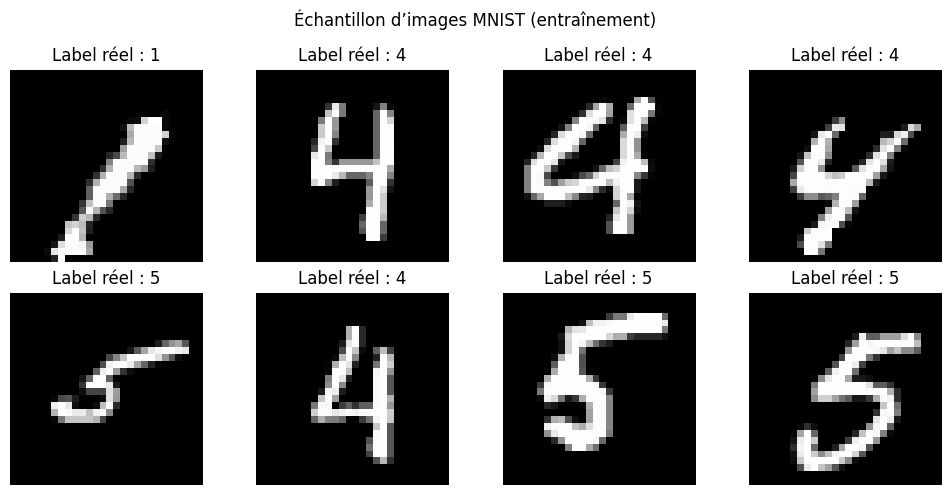

In [5]:
import matplotlib.pyplot as plt

# Échantillon de 8 images du jeu d'entraînement
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    # Annuler la normalisation pour afficher l'image en niveaux de gris
    image_to_show = image.squeeze(0) * 0.3081 + 0.1307
    ax.imshow(image_to_show.numpy(), cmap='gray')
    ax.set_title(f"Label réel : {label.item()}")
    ax.axis('off')
plt.suptitle('Échantillon d’images MNIST (entraînement)')
plt.tight_layout()
plt.show()


## Définir le CNN

Le réseau utilise trois convolutions, BatchNorm, ReLU, max pooling, dropout et deux couches entièrement connectées. La dernière couche renvoie 10 logits, un par chiffre.


In [6]:
class MNIST_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                    # 32 x 14 x 14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                    # 64 x 7 x 7
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Dropout2d(0.15)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.40),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = MNIST_CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
print(model)


MNIST_CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Dropout2d(p=0.15, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=128, bias=True)
    (2): ReLU(inplace=True)
    (3): 

## Entraînement avec early stopping

Le meilleur état du modèle est choisi sur la perte de validation. L’entraînement s’arrête après plusieurs époques sans amélioration.


In [7]:
def run_epoch(loader, training=False):
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

EPOCHS = 30
PATIENCE = 6
best_val_loss = float('inf')
best_state = None
no_improve = 0
history = []
start = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    scheduler.step(val_loss)
    history.append((epoch, train_loss, train_acc, val_loss, val_acc))
    print(f"Epoch {epoch:02d} | train loss {train_loss:.4f}, acc {train_acc:.4f} | val loss {val_loss:.4f}, acc {val_acc:.4f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        no_improve = 0
    else:
        no_improve += 1
    if no_improve >= PATIENCE:
        print('Early stopping.')
        break

model.load_state_dict(best_state)
training_seconds = time.time() - start
print(f"Temps d'entraînement : {training_seconds:.1f} secondes")


Epoch 01 | train loss 0.2381, acc 0.9258 | val loss 0.0582, acc 0.9807
Epoch 02 | train loss 0.1028, acc 0.9691 | val loss 0.0419, acc 0.9872
Epoch 03 | train loss 0.0858, acc 0.9746 | val loss 0.0414, acc 0.9880
Epoch 04 | train loss 0.0749, acc 0.9775 | val loss 0.0293, acc 0.9903
Epoch 05 | train loss 0.0649, acc 0.9814 | val loss 0.0269, acc 0.9922
Epoch 06 | train loss 0.0605, acc 0.9818 | val loss 0.0304, acc 0.9907
Epoch 07 | train loss 0.0561, acc 0.9831 | val loss 0.0298, acc 0.9907
Epoch 08 | train loss 0.0524, acc 0.9848 | val loss 0.0304, acc 0.9902
Epoch 09 | train loss 0.0400, acc 0.9882 | val loss 0.0201, acc 0.9945
Epoch 10 | train loss 0.0360, acc 0.9889 | val loss 0.0188, acc 0.9938
Epoch 11 | train loss 0.0361, acc 0.9892 | val loss 0.0232, acc 0.9912
Epoch 12 | train loss 0.0324, acc 0.9905 | val loss 0.0191, acc 0.9943
Epoch 13 | train loss 0.0342, acc 0.9897 | val loss 0.0217, acc 0.9937
Epoch 14 | train loss 0.0261, acc 0.9922 | val loss 0.0157, acc 0.9955
Epoch 

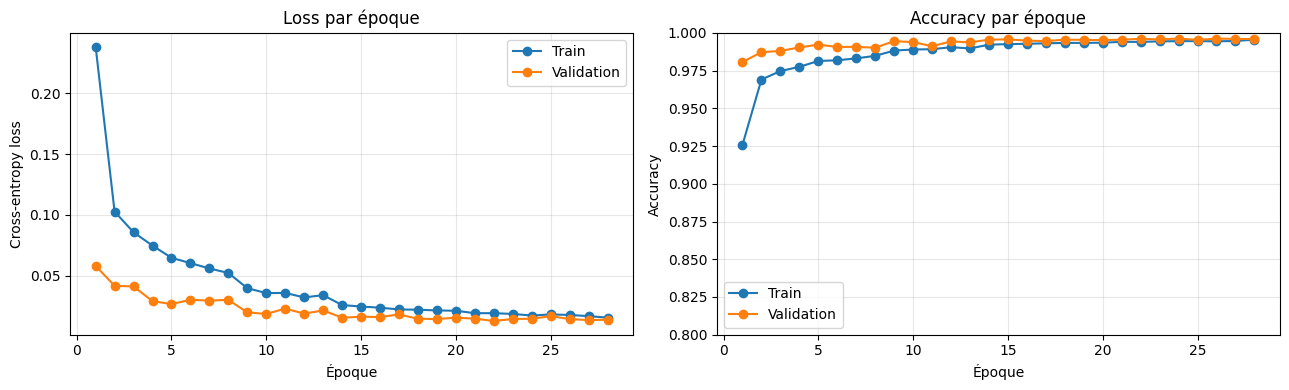

In [8]:
# Tracer loss et accuracy pour entraînement et validation
epochs = [row[0] for row in history]
train_losses = [row[1] for row in history]
train_accuracies = [row[2] for row in history]
val_losses = [row[3] for row in history]
val_accuracies = [row[4] for row in history]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs, train_losses, marker='o', label='Train')
axes[0].plot(epochs, val_losses, marker='o', label='Validation')
axes[0].set_title('Loss par époque')
axes[0].set_xlabel('Époque')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, train_accuracies, marker='o', label='Train')
axes[1].plot(epochs, val_accuracies, marker='o', label='Validation')
axes[1].set_title('Accuracy par époque')
axes[1].set_xlabel('Époque')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0.8, 1.0)
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()


## Évaluation finale sur le jeu de test

Accuracy, F1 macro, perte et rapport par classe sont calculés avec le meilleur modèle sauvegardé.


In [9]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

model.eval()
all_preds, all_labels = [], []
test_loss_total, n_test = 0.0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels_gpu = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels_gpu)
        test_loss_total += loss.item() * labels.size(0)
        n_test += labels.size(0)
        all_preds.extend(logits.argmax(1).cpu().tolist())
        all_labels.extend(labels.tolist())

test_loss = test_loss_total / n_test
test_accuracy = accuracy_score(all_labels, all_preds)
test_f1_macro = f1_score(all_labels, all_preds, average='macro')
print(f"Temps d'entraînement : {training_seconds:.1f} s")
print(f"Test loss            : {test_loss:.4f}")
print(f"Test accuracy        : {test_accuracy:.4f}")
print(f"Test F1 macro        : {test_f1_macro:.4f}")
print('\nRapport par classe :')
print(classification_report(all_labels, all_preds, digits=4))

model_path = str(WORK_DIR / 'mnist_cnn_best.pth')
torch.save(model.state_dict(), model_path)
print('Modèle sauvegardé :', model_path)


Temps d'entraînement : 483.7 s
Test loss            : 0.0121
Test accuracy        : 0.9957
Test F1 macro        : 0.9957

Rapport par classe :
              precision    recall  f1-score   support

           0     0.9949    0.9990    0.9969       980
           1     0.9956    0.9974    0.9965      1135
           2     0.9952    0.9981    0.9966      1032
           3     0.9931    0.9980    0.9956      1010
           4     0.9939    0.9959    0.9949       982
           5     0.9966    0.9922    0.9944       892
           6     0.9979    0.9948    0.9963       958
           7     0.9951    0.9961    0.9956      1028
           8     0.9990    0.9938    0.9964       974
           9     0.9960    0.9911    0.9935      1009

    accuracy                         0.9957     10000
   macro avg     0.9957    0.9956    0.9957     10000
weighted avg     0.9957    0.9957    0.9957     10000

Modèle sauvegardé : /content/Atelier2_DeepLearning/.runs/cnn/mnist_cnn_best.pth


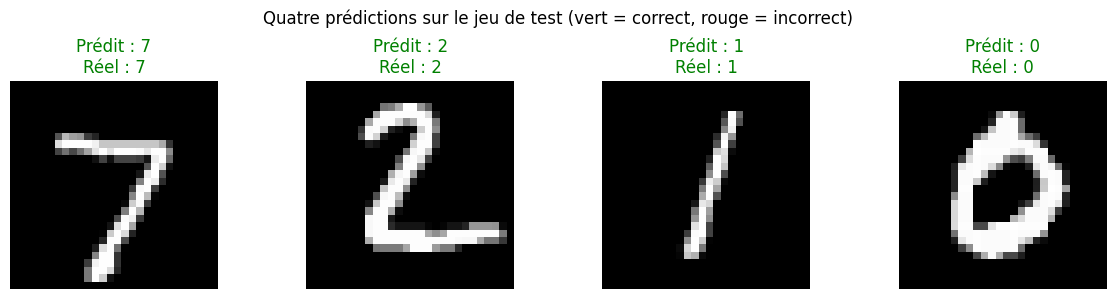

In [10]:
# Afficher quatre images du test et la prédiction du modèle
images, labels = next(iter(test_loader))
images_gpu = images[:4].to(device)
with torch.no_grad():
    predictions = model(images_gpu).argmax(dim=1).cpu()

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axes):
    image_to_show = images[i].squeeze(0) * 0.3081 + 0.1307
    pred = predictions[i].item()
    true = labels[i].item()
    color = 'green' if pred == true else 'red'
    ax.imshow(image_to_show.numpy(), cmap='gray')
    ax.set_title(f"Prédit : {pred}\nRéel : {true}", color=color)
    ax.axis('off')
plt.suptitle('Quatre prédictions sur le jeu de test (vert = correct, rouge = incorrect)')
plt.tight_layout()
plt.show()


## Interprétation

Compare les courbes train/validation et les scores finaux. Si l’accuracy train continue d’augmenter alors que la perte validation remonte, cela indique un début de surapprentissage ; l’early stopping restaure alors l’état ayant obtenu la meilleure perte de validation.


## Enregistrer cette nouvelle exécution

Les métriques sont calculées depuis les prédictions de cette session GPU. Le dossier
`results/adapted_gpu/` reste distinct des résultats importés et des anciens profils.
Enregistrer aussi le notebook dans GitHub **avec ses sorties**. L'archive permet de
conserver les résultats, même si les cinq modèles ne sont pas tous terminés.

In [11]:
result = save_result('cnn', all_labels, all_preds, test_loss, training_seconds, WORK_DIR)
from scripts.export_adapted_results import export
archive = export(allow_partial=True)
print('Archive :', archive)
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Archive disponible localement.')

Nouvelle exécution GPU enregistrée : /content/Atelier2_DeepLearning/results/adapted_gpu/cnn
/content/Atelier2_DeepLearning/resultats_adaptes_atelier2_partiel.zip
Archive : /content/Atelier2_DeepLearning/resultats_adaptes_atelier2_partiel.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>